# 23 · Final Improvement Round (v4): Self-Training, Two-Stage Detection and an Ensemble

**The question:** Notebook 22 showed that most of the remaining error on the official test file comes from the **shift** between the training and test
files (and, for attack types, from identical flows with different labels). Can methods that **adapt to the new traffic without its labels** close part
of that gap?

| | |
|---|---|
| **Input** | Detector v3 (Notebook 22), the training file roles, the **measurements** of the test file (no labels), the importance weights of Notebook 20 |
| **What we do** | Fix five candidates in advance; train them without test labels; calibrate each on the calibration rows; choose with the importance-weighted macro F1 on the model_selection rows; evaluate the chosen one **once** on the test file; deploy it only if it is clearly better than v3 |
| **Output** | Detector v4 (or v3 stays), the final scores of the project |

**Disclosure:** this is the **fourth and final** look at the test labels (Notebooks 19, 21, 22, 23). Everything up to section 7 uses the test file's
measurements only (as Notebook 20 did); the labels are loaded once, in section 7. **Self-training** (C2, C4) uses the test flows' measurements and the
model's own predictions on them, never their labels: this is *transductive* learning and is reported as such. After this notebook the model is frozen.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy import sparse
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

from src.notebook_helpers import TRAIN_CSV, TEST_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style
from src.final_detector import FinalDetector, Preprocessor, load_raw, apply_temperature, apply_bias, dense
from src.flow_networks import class_weights
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train'] and sha256(TEST_CSV) == RAW_SHA256['test']
NORMAL = CLASSES.index('Normal')

pre = Preprocessor()
raw = {r: load_raw(r) for r in ['train', 'model_selection', 'calibration']}
test_features = load_raw('test').drop(columns=['id', 'label', 'attack_cat'])          # labels dropped here; loaded only in section 7
assert not {'label', 'attack_cat'} & set(test_features.columns)
X = {r: pre.transform(f)['tree'] for r, f in raw.items()}
X['test'] = pre.transform(test_features)['tree']
y = {r: pd.Categorical(f.attack_cat, categories=CLASSES).codes.astype(int) for r, f in raw.items()}
print({k: v.shape for k, v in X.items()})

{'train': (140273, 195), 'model_selection': (17534, 195), 'calibration': (17534, 195), 'test': (82332, 195)}


## 2. The importance weights of Notebook 20, reproduced exactly

Notebook 20 saved the weights of the calibration and model_selection rows, but training needs the weights of the **training** rows too. We recompute
them with exactly the same code (adversarial classifier, 5-fold out-of-fold, cap at the 99th percentile) and check that they match the saved ones.

In [2]:
train_file = sparse.vstack([X['train'], X['model_selection'], X['calibration']]).tocsr()
domain_X = sparse.vstack([train_file, X['test']]).tocsr()
domain_y = np.r_[np.zeros(train_file.shape[0]), np.ones(X['test'].shape[0])]
oof = np.zeros(len(domain_y))
for a, b in StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(np.zeros(len(domain_y)), domain_y):
    m = LGBMClassifier(n_estimators=200, num_leaves=31, learning_rate=0.1, random_state=0, n_jobs=8, verbosity=-1)
    m.fit(domain_X[a], domain_y[a])
    oof[b] = m.predict_proba(domain_X[b])[:, 1]
n_file, n_test = train_file.shape[0], X['test'].shape[0]
p_file = np.clip(oof[:n_file], 1e-6, 1 - 1e-6)
ratio = np.minimum(p_file / (1 - p_file) * n_file / n_test, np.percentile(p_file / (1 - p_file) * n_file / n_test, 99))
sizes = [X[r].shape[0] for r in ['train', 'model_selection', 'calibration']]
raw_w = dict(zip(['train', 'model_selection', 'calibration'], np.split(ratio, np.cumsum(sizes)[:-1])))
saved = np.load(DATA / '20_importance_weights.npz')
for r in ['model_selection', 'calibration']:
    assert np.allclose(raw_w[r], saved[r]), f'importance weights of {r} differ from Notebook 20'
w = {r: v / v.mean() for r, v in raw_w.items()}
print(f'adversarial AUC {roc_auc_score(domain_y, oof):.3f}; weights reproduced exactly for model_selection and calibration')

adversarial AUC 0.896; weights reproduced exactly for model_selection and calibration


## 3. The candidates (fixed before any result)

| Candidate | Idea | Why it might help |
|---|---|---|
| C0 | **v3** as deployed | baseline |
| C1 | **two-stage**: a dedicated attack-vs-normal LightGBM gives P(normal); v3's base model gives the shares of the attack types | a model trained only for the main task may separate attack from normal better |
| C2 | **self-training**: v3 labels the test flows it is at least 95% sure about; LightGBM (v2 settings) is retrained on the training rows plus these flows | the model sees the new traffic's measurement patterns, without their labels |
| C3 | **ensemble**: v2's LightGBM averaged with an XGBoost trained the same way | two different tree learners make different mistakes |
| C4 | **self-training + ensemble** | both |

Every candidate then gets the same treatment as v3: a temperature fitted on the calibration rows (importance-weighted log-loss) and class offsets fitted on
the calibration rows (importance-weighted macro F1). **Selection:** highest importance-weighted macro F1 on the model_selection rows. **Deployment:** only if
the whole 95% bootstrap interval of the test macro F1 difference to v3 is above zero.

In [3]:
v3 = FinalDetector.load('v3')
spec_v2 = read_json(MODELS / 'final_detector_v2.json')
class_w = class_weights(y['train'], 'sqrt')
train_w = class_w[y['train']] * w['train']                          # exactly the v2 training weights


def make_lgbm():
    return LGBMClassifier(objective='multiclass', n_estimators=400, learning_rate=0.05, num_leaves=31, reg_lambda=1.0, min_child_samples=20,
                          random_state=42, n_jobs=8, deterministic=True, force_col_wise=True, verbosity=-1)


def make_xgb():
    return XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                         objective='multi:softprob', eval_metric='mlogloss', random_state=42, n_jobs=8)


# Self-training data: v3's confident predictions on the test measurements (no labels)
p_test_v3 = v3.predict_proba(test_features)
confident = p_test_v3.max(1) >= 0.95
pseudo_y = p_test_v3.argmax(1)[confident]
print(f'pseudo-labelled test flows (confidence >= 95%): {confident.sum():,} of {len(confident):,}')
display(pd.Series(pseudo_y).map(dict(enumerate(CLASSES))).value_counts().rename('pseudo-labelled flows').to_frame().T)
X_self = sparse.vstack([X['train'], X['test'][confident]]).tocsr()
y_self = np.r_[y['train'], pseudo_y]
w_self = np.r_[train_w, class_w[pseudo_y]]

paths = {'lgbm_self': 'models/v3/23_lightgbm_selftrained.joblib', 'xgb': 'models/v3/23_xgboost.joblib',
         'xgb_self': 'models/v3/23_xgboost_selftrained.joblib', 'binary': 'models/v3/23_attack_vs_normal.joblib'}
root = MODELS.parent.parent
joblib.dump(make_lgbm().fit(X_self, y_self, sample_weight=w_self), root / paths['lgbm_self'])
joblib.dump(make_xgb().fit(dense(X['train']), y['train'], sample_weight=train_w), root / paths['xgb'])
joblib.dump(make_xgb().fit(dense(X_self), y_self, sample_weight=w_self), root / paths['xgb_self'])
binary = LGBMClassifier(objective='binary', n_estimators=400, learning_rate=0.05, num_leaves=31, reg_lambda=1.0, random_state=42, n_jobs=8,
                        deterministic=True, force_col_wise=True, verbosity=-1)
joblib.dump(binary.fit(X['train'], (y['train'] != NORMAL).astype(int), sample_weight=w['train']), root / paths['binary'])

base = {k: v for k, v in spec_v2.items() if k not in ('iw_macro_f1_estimate',)}
specs = {
    'C1 two-stage': base | {'binary_model': paths['binary']},
    'C2 self-training': base | {'lightgbm_model': paths['lgbm_self']},
    'C3 ensemble (LightGBM + XGBoost)': base | {'xgboost_model': paths['xgb']},
    'C4 self-training + ensemble': base | {'lightgbm_model': paths['lgbm_self'], 'xgboost_model': paths['xgb_self']},
}
print('candidates trained:', list(specs))

pseudo-labelled test flows (confidence >= 95%): 43,927 of 82,332


,Normal,Generic,Reconnaissance,Exploits,Backdoor,Fuzzers,Analysis,DoS,Worms,Shellcode
pseudo-labelled flows,21244,18153,2472,1514,274,152,59,39,16,4


candidates trained: ['C1 two-stage', 'C2 self-training', 'C3 ensemble (LightGBM + XGBoost)', 'C4 self-training + ensemble']


## 4. Calibrate every candidate on the calibration rows (temperature, then class offsets)

In [4]:
GRID = np.round(np.linspace(-3, 3, 61), 2)


def iw_f1(true, pred, sample_weight):
    return f1_score(true, pred, average='macro', labels=range(10), sample_weight=sample_weight, zero_division=0)


def fit_temperature(p_raw):
    def nll(t):
        p = apply_temperature(p_raw, t)
        return float(-(w['calibration'] * np.log(np.clip(p[np.arange(len(p)), y['calibration']], 1e-12, 1))).sum() / w['calibration'].sum())
    return float(minimize_scalar(nll, bounds=(0.05, 20), method='bounded').x)


def fit_offsets(proba, rounds=3):
    b, logp = np.zeros(10), np.log(np.clip(proba, 1e-12, 1))
    for _ in range(rounds):
        for k in range(10):
            gains = []
            for g in GRID:
                trial = b.copy(); trial[k] = g
                gains.append(iw_f1(y['calibration'], (logp + trial).argmax(1), w['calibration']))
            b[k] = GRID[int(np.argmax(gains))]
    return b


detectors = {'C0 v3 (deployed)': v3}
for name, spec in specs.items():
    d = FinalDetector(spec)
    d.temperature = fit_temperature(d.predict_proba(raw['calibration'], calibrated=False))
    d.class_bias = fit_offsets(apply_temperature(d.predict_proba(raw['calibration'], calibrated=False), d.temperature))
    d.spec = spec | {'temperature': d.temperature, 'class_bias': [float(b) for b in d.class_bias]}
    detectors[name] = d
    print(f'{name:34s} temperature {d.temperature:.3f}')

C1 two-stage                       temperature 1.082


C2 self-training                   temperature 1.161


C3 ensemble (LightGBM + XGBoost)   temperature 1.179


C4 self-training + ensemble        temperature 1.184


## 5. Selection on the model_selection rows (no test labels)

,IW macro F1,IW accuracy,IW attack F1,IW attack recall,IW false-alarm rate,plain macro F1,plain accuracy
C0 v3 (deployed),0.7155,0.8040,0.9349,0.9575,0.1769,0.6621,0.8136
C1 two-stage,0.7103,0.7969,0.9301,0.9716,0.2291,0.6614,0.8144
C2 self-training,0.6966,0.8014,0.9350,0.9645,0.1918,0.6465,0.8126
C3 ensemble (LightGBM + XGBoost),0.7141,0.8131,0.9383,0.9548,0.1564,0.6647,0.8211
C4 self-training + ensemble,0.7032,0.8010,0.9335,0.9680,0.2063,0.6552,0.8159


chosen by the rule: C0 v3 (deployed)


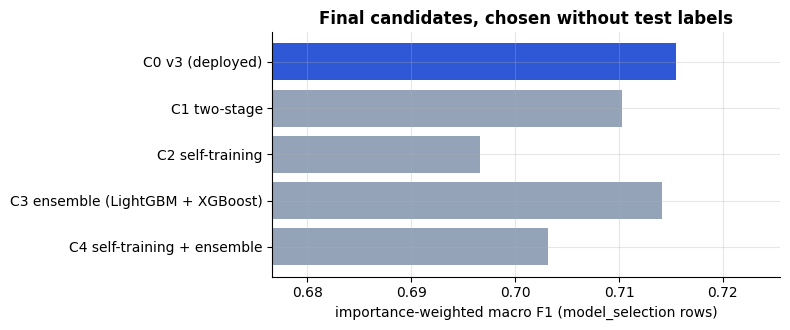

In [5]:
def scores(true, pred, sample_weight=None):
    sw = np.ones(len(true)) if sample_weight is None else sample_weight
    attack, flagged = true != NORMAL, pred != NORMAL
    tp, fp = (sw * (attack & flagged)).sum(), (sw * (~attack & flagged)).sum()
    fn, tn = (sw * (attack & ~flagged)).sum(), (sw * (~attack & ~flagged)).sum()
    return {'macro F1': iw_f1(true, pred, sample_weight), 'accuracy': np.average(pred == true, weights=sw),
            'attack F1': 2 * tp / (2 * tp + fp + fn), 'attack recall': tp / (tp + fn), 'false-alarm rate': fp / (fp + tn)}


rows = {}
for name, d in detectors.items():
    pred = d.predict_proba(raw['model_selection']).argmax(1)
    rows[name] = {**{f'IW {k}': v for k, v in scores(y['model_selection'], pred, w['model_selection']).items()},
                  'plain macro F1': iw_f1(y['model_selection'], pred, None), 'plain accuracy': accuracy_score(y['model_selection'], pred)}
selection = pd.DataFrame(rows).T
CHOSEN = selection['IW macro F1'].idxmax()
save_table(selection, '23_candidates_model_selection', index=True)
display(selection.round(4))
print('chosen by the rule:', CHOSEN)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(selection.index[::-1], selection['IW macro F1'][::-1], color=['#2f58d6' if n == CHOSEN else '#94a3b8' for n in selection.index[::-1]])
ax.set(xlim=(selection['IW macro F1'].min() - 0.02, selection['IW macro F1'].max() + 0.01), xlabel='importance-weighted macro F1 (model_selection rows)',
       title='Final candidates, chosen without test labels')
plt.tight_layout(); save_figure(fig, '23_candidates'); plt.show()

## 6. The chosen detector keeps trustworthy probabilities and shortlists

In [6]:
def conformal_thresholds(proba, true, alpha=0.1):
    out = []
    for k in range(10):
        s = np.sort(1 - proba[true == k, k])
        rank = int(np.ceil((len(s) + 1) * (1 - alpha)))
        out.append(float(1 - (s[rank - 1] if rank <= len(s) else 1.0)))
    return out


def ece(proba, true, bins=15):
    conf, pred = proba.max(1), proba.argmax(1)
    edges, total = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs((pred[m] == true[m]).mean() - conf[m].mean())
    return total


chosen = detectors[CHOSEN]
thresholds = conformal_thresholds(chosen.predict_proba(raw['calibration']), y['calibration'])
p_ms = chosen.predict_proba(raw['model_selection'])
sets = p_ms >= np.asarray(thresholds)[None, :]
print(f"ECE on model_selection: v3 {ece(v3.predict_proba(raw['model_selection']), y['model_selection']):.4f} | {CHOSEN} {ece(p_ms, y['model_selection']):.4f}")
print(f"90% set coverage on model_selection: {sets[np.arange(len(sets)), y['model_selection']].mean():.3f}")

ECE on model_selection: v3 0.0441 | C0 v3 (deployed) 0.0441
90% set coverage on model_selection: 0.913


## 7. The final look at the test file

In [7]:
y_test = pd.Categorical(load_raw('test').attack_cat, categories=CLASSES).codes.astype(int)
results, test_proba = {}, {}
for name, d in detectors.items():
    proba = d.predict_proba(test_features)
    test_proba[name] = proba
    pred = proba.argmax(1)
    results[name] = {**scores(y_test, pred), 'weighted F1': f1_score(y_test, pred, average='weighted'),
                     'top-2 accuracy': float((np.argsort(-proba, 1)[:, :2] == y_test[:, None]).any(1).mean())}
test_table = pd.DataFrame(results).T
save_table(test_table, '23_candidates_test', index=True)
display(test_table.round(4))
rho = spearmanr(selection['IW macro F1'], test_table['macro F1']).correlation
print(f'rank agreement between the label-free estimate and the test macro F1 (Spearman): {rho:.2f}')

rng = np.random.default_rng(0)
boot = rng.integers(0, len(y_test), size=(1000, len(y_test)), dtype=np.int32)
pred_v3, pred_new = test_proba['C0 v3 (deployed)'].argmax(1), test_proba[CHOSEN].argmax(1)
diffs = [iw_f1(y_test[i], pred_new[i], None) - iw_f1(y_test[i], pred_v3[i], None) for i in boot]
low, high = np.percentile(diffs, [2.5, 97.5])
change = iw_f1(y_test, pred_new, None) - iw_f1(y_test, pred_v3, None)
DEPLOY = bool(CHOSEN != 'C0 v3 (deployed)' and low > 0)
print(f'macro F1 {CHOSEN} - v3: {change:+.4f} (95% interval {low:+.4f} to {high:+.4f}) -> deploy v4: {DEPLOY}')

,macro F1,accuracy,attack F1,attack recall,false-alarm rate,weighted F1,top-2 accuracy
C0 v3 (deployed),0.5415,0.7447,0.8882,0.9763,0.2720,0.7793,0.9123
C1 two-stage,0.5254,0.7286,0.8819,0.9887,0.3105,0.7692,0.8996
C2 self-training,0.5157,0.7392,0.8859,0.9805,0.2857,0.7756,0.9085
C3 ensemble (LightGBM + XGBoost),0.5426,0.7499,0.8902,0.9729,0.2609,0.7810,0.9126
C4 self-training + ensemble,0.5333,0.7345,0.8800,0.9794,0.3019,0.7715,0.9129


rank agreement between the label-free estimate and the test macro F1 (Spearman): 0.80


macro F1 C0 v3 (deployed) - v3: +0.0000 (95% interval +0.0000 to +0.0000) -> deploy v4: False


## 8. Per-class view against the ceiling (for the paper)

For every class: the F1 of the final detector and the F1 of the "memoriser" that knows the test labels (Notebook 22). Where the memoriser itself is low,
the class cannot be separated by these 42 measurements.

In [8]:
final_name = CHOSEN if DEPLOY else 'C0 v3 (deployed)'
test_raw = load_raw('test')
key = test_raw[pre.predictors].astype(str).agg('|'.join, axis=1)
memoriser = pd.Categorical(key.map(test_raw.groupby(key).attack_cat.agg(lambda s: s.value_counts().index[0])), categories=CLASSES).codes
per_class = pd.DataFrame({'final detector F1': f1_score(y_test, test_proba[final_name].argmax(1), average=None, labels=range(10)),
                          'best possible F1 (ceiling)': f1_score(y_test, memoriser, average=None, labels=range(10)),
                          'test flows': np.bincount(y_test, minlength=10)}, index=CLASSES)
per_class['share of the ceiling'] = per_class['final detector F1'] / per_class['best possible F1 (ceiling)']
save_table(per_class, '23_per_class_ceiling', index=True)
display(per_class.round(3))

,final detector F1,best possible F1 (ceiling),test flows,share of the ceiling
Analysis,0.0580,0.1580,677,0.3690
Backdoor,0.0340,0.1900,583,0.1810
DoS,0.4120,0.6770,4089,0.6080
Exploits,0.6940,0.8060,11132,0.8610
Fuzzers,0.3660,0.8830,6062,0.4150
Generic,0.9840,0.9990,18871,0.9850
Normal,0.8290,1.0000,37000,0.8290
Reconnaissance,0.8620,0.9480,3496,0.9090
Shellcode,0.5400,0.9990,378,0.5410
Worms,0.6350,0.9890,44,0.6430


## 9. Save the final detector

In [9]:
spec_v4 = chosen.spec | {'name': f'LightGBM v4 ({CHOSEN.split(" ", 1)[1]}, chosen without test labels)', 'conformal_thresholds': thresholds,
                         'deployed': DEPLOY, 'test_labels_used': False,
                         'selection': 'importance-weighted macro F1 on model_selection rows; temperature and offsets fitted on calibration rows'}
save_json(spec_v4, MODELS / 'final_detector_v4.json')
save_json({'chosen': CHOSEN, 'deployed': DEPLOY, 'final': final_name, 'v3': test_table.loc['C0 v3 (deployed)'].to_dict(),
           'v4': test_table.loc[CHOSEN].to_dict(), 'macro F1 change vs v3': change, 'bootstrap 95% interval': [low, high], 'rank agreement': rho,
           'pseudo_labelled_test_flows': int(confident.sum()),
           'disclosure': 'fourth and final use of the test labels; self-training uses test measurements and model predictions, never test labels'},
          MODELS / '23_final_results_v4.json')
check = FinalDetector.load('v4').predict_proba(test_features.head(2000))
assert np.allclose(check, test_proba[CHOSEN][:2000], atol=1e-9), 'saved v4 does not reproduce the evaluated probabilities'
print('saved:', spec_v4['name'], '| deployed:', DEPLOY)

saved: LightGBM v4 (v3 (deployed), chosen without test labels) | deployed: False


## What we learned

The table in section 7 answers the question honestly: it shows how much adapting to the new traffic without labels (self-training), a dedicated
attack-vs-normal model and an ensemble change the official test scores, and whether the label-free selection rule picked a better detector than v3.
The per-class table shows which attack types are limited by the data itself.

## What is still uncertain

- Four looks at the test labels in total (each disclosed, each choice made without labels); small differences may partly reflect this split.
- Self-training can reinforce the model's own mistakes on the pseudo-labelled flows; only flows with at least 95% confidence were used.

## What comes next

The model is frozen after this notebook. The application serves v4 if it was deployed, otherwise v3.